# Weeks 5 & 6 Exercises

Author: Rosie Navarro

date: October 5, 2026


## Exercise 1: Activity 5.01

Reading Tabular Data from a Web Page and Creating DataFrames

In [1]:
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import sqlite3

The page is read using bs4.

In [2]:
fd = open("/Users/rosienavarro/Data_Science/List of countries by GDP (nominal) - Wikipedia.html", "r", encoding = "utf-8")
soup = BeautifulSoup(fd)
fd.close()

The next step is to find the total number of tables in this html file. bs4 can be used to find the right table

In [3]:
tables = soup.find_all("table")
len(tables)

8

In [7]:
data_table = soup.find("table", {"class" : "wikitable"})
print(type(data_table))

<class 'bs4.element.Tag'>


There is a total of 8 tables. The table that we need to find is a table that has wikitable. 

The next step is to separate the source names with its data. 

In [17]:
source = data_table.tbody.find_all('tr', recursive=False)[0]


source_list = [th for th in source.find_all('th')]
print(len(source_list))

4


In [40]:
header1 = [th.getText("", strip=True)
           for th in data_table.find_all("th")]

header1

['Country/Territory',
 'IMF(2026)[1]',
 'World Bank(2025)[6]',
 'United Nations(2024)[7]']

In [41]:
# Extracts headers
header_list = [th.get_text(" ", strip=True)
               for th in header.find_all('th')]

In [50]:
row = data_table.find_all("tr")
for row in row[:5]:
    print([cell.get_text("", strip=True) for cell in row.find_all(["th", "td"], recursive=False)])

['Country/Territory', 'IMF(2026)[1]', 'World Bank(2025)[6]', 'United Nations(2024)[7]']
['World', '126,295,331', '118,350,166', '111,565,144']
['United States', '32,383,920', '30,769,700', '29,298,000']
['China[n 1]', '20,851,593', '19,498,039', '18,743,802']
['Germany', '5,452,858', '5,050,923', '4,659,929']


In [51]:
# Data Collection
data = []

for row in rows:
    cells = row.find_all(["th", "td"], recursice=False)
    if len(cells) == 4:
        data.append([cell.get_text("", strip=True) for cell in cells])

The following is how the data frame was created, and the data is displayed using head. 

In [72]:
df1 = pd.DataFrame(
    [[row[0], row[1]] for row in data[1:]],
    columns=["Country/Territory", "IMF(2026)[1]"])
df1.head()

,Country/Territory,IMF(2026)[1]
0,World,"126,295,331"
1,United States,"32,383,920"
2,China[n 1],"20,851,593"
3,Germany,"5,452,858"
4,Japan,"4,379,253"


Repeat steps for the second and third dataframe- not all of the steps need to be completed (rows and header step), the only step that needs to be completed is creating the dataframe. 

In [55]:
df2 = pd.DataFrame(
    [[row[0], row[1]] for row in data[1:]],
    columns=["Country/Territory", "World Bank(2025)[6]"])
df2.head()

,Country/Territory,World Bank(2025)[6]
0,World,"126,295,331"
1,United States,"32,383,920"
2,China[n 1],"20,851,593"
3,Germany,"5,452,858"
4,Japan,"4,379,253"


In [56]:
df3 = pd.DataFrame(
    [[row[0], row[1]] for row in data[1:]],
    columns=["Country/Territory", "United Nations(2024)[7]"])
df3.head()

,Country/Territory,United Nations(2024)[7]
0,World,"126,295,331"
1,United States,"32,383,920"
2,China[n 1],"20,851,593"
3,Germany,"5,452,858"
4,Japan,"4,379,253"


One thing that I found interesting during this week's assignment is that the wikipedia page was not the same one used in the assignment, it had similar information but it did not contain information about GDP. 

## Exercise 2: Activity 6.01

Handling Outliers and Missing Data

The first step is to make sure that the data was loaded correctly. 

In [17]:
df = pd.read_csv("/Users/rosienavarro/Data_Science/visit_data.csv")
df.head(20)

,id,first_name,last_name,email,gender,ip_address,visit
0,1,Sonny,Dahl,sdahl0@mysql.com,Male,135.36.96.183,1225.0
1,2,NaN,NaN,dhoovart1@hud.gov,NaN,237.165.194.143,919.0
2,3,Gar,Armal,garmal2@technorati.com,NaN,166.43.137.224,271.0
3,4,Chiarra,Nulty,cnulty3@newyorker.com,NaN,139.98.137.108,1002.0
4,5,NaN,NaN,sleaver4@elegantthemes.com,NaN,46.117.117.27,2434.0
5,6,Raymund,Ingerfield,ringerfield5@microsoft.com,NaN,90.100.118.215,451.0
6,7,Wilhelmina,Dagnan,wdagnan6@nytimes.com,Female,88.133.77.243,1540.0
7,8,NaN,NaN,mdewilde7@creativecommons.org,Female,229.215.244.227,537.0
8,9,Gunter,Lisamore,glisamore8@disqus.com,NaN,134.185.44.82,743.0
9,10,Luelle,Scinelli,lscinelli9@issuu.com,Female,160.130.58.61,1507.0


At first glance, you can see that there are many missing values in the data espcailly the last names and first names. 

In [18]:

print("First name is duplicated - {}".format(any(df.first_name.duplicated())))
print("Last name is duplicated - {}".format(any(df.last_name.duplicated())))
print("Email is duplicated - {}".format(any(df.email.duplicated())))

First name is duplicated - True
Last name is duplicated - True
Email is duplicated - False


In [19]:
print("The column Email contains NaN - %r " % df.email.isnull().values.any())
print("The column IP Address contains NaN - %s " % df.ip_address.isnull().values.any())
print("The column Visit contains NaN - %s " % df.visit.isnull().values.any())

The column Email contains NaN - np.False_ 
The column IP Address contains NaN - False 
The column Visit contains NaN - True 


In [20]:
size_prev = df.shape
df = df[np.isfinite(df['visit'])] #This is an inplace operation. After this operation the original DataFrame is lost.
size_after = df.shape


In [21]:
print("The size of previous data was - {prev[0]} rows and the size of the new one is - {after[0]} rows".
format(prev=size_prev, after=size_after))

The size of previous data was - 1000 rows and the size of the new one is - 974 rows


Different graphs can be created but in this case, a boxplot will be made. You can see the range of the date and thw quartiles (Q1, Q3, and median. 

{'whiskers': [<matplotlib.lines.Line2D at 0x113122db0>,
 'caps': [<matplotlib.lines.Line2D at 0x1131cbc50>,
 'boxes': [<matplotlib.lines.Line2D at 0x113093290>],
 'medians': [<matplotlib.lines.Line2D at 0x1131ec1d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1131ec470>],
 'means': []}

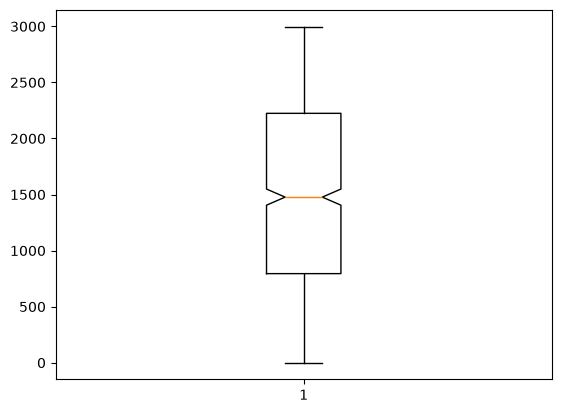

In [22]:
plt.boxplot(df.visit, notch=True)

In [23]:

df4 = df[(df['visit'] <= 2900) & (df['visit'] >= 100)]  # Notice the power-ful & operator
# Here we abuse the fact the number of variable can be greater than the num-ber of replacement targets
print("After getting rid of outliers the new size of the data is - {}".format(*df4.shape))

After getting rid of outliers the new size of the data is - 923


## Exercise 3: 

Inserting data into SQL Lite. For this part of the assignment it must contain: a. Name, Address, City, State, Zip, Phone Number b. Add at least 10 rows of data and submit your code with a query generating your results.


The first step is to connect to SQLite. 

In [2]:
conn = sqlite3.connect("contacts.db")

Once it is connected the next step is to create the table with the following varibles mentioned previously. 

In [4]:
query = """
CREATE TABLE IF NOT EXISTS contacts (
Name TEXT,
Address TEXT, 
City TEXT, 
State TEXT, 
Zip Text, 
Phone Text);
"""
conn.execute(query)

The next part is to create that data that will be found in the table. It has to have aleast 10 different rows. 

In [12]:
data = [
    ("Jane Alvarez", "283 Wax Street", "Salt lake City", "UT", "93224", "903-9042-8984"),
    ("Mike White", "1902 Can Street", "Salt lake City", "UT", "19223", "902-846-4490"), 
    ("Rose Yellow", "1903 Whine Street", "Detroit", "MI", "091889", "191-1937-4567"), 
    ("Joan Liow", "193 wuio Street", "Salt lake City", "UT", "13553", "132-903-2875"), 
    ("Jacob Sekl", "453 skle Street", "Salt Lake City", "UT", "12354", "129-485-2905"), 
    ("Taylor wek", "2890 Street", "Salt Lake City", "UT", "89300", "190-385-2904"), 
    ("Jane Alex", "283 Maker Street", "Salt lake City", "UT", "29098", "903-9042-8898"),
    ("Alex White", "189 sjkle Street", "Salt lake City", "UT", "34556", "902-233-4340"), 
    ("Rose Yellow", "190 232 Street", "Detroit", "MI", "46225", "245-354-6765"), 
    ("Joan Liow", "1932 wrew Street", "Salt lake City", "UT", "54778", "132-343-4654"), 
    ("Jacob Sekl", "455 fk4 Street", "Salt Lake City", "UT", "54783", "129-422-3654"), 
    ("Taylor wek", "3 jei Street", "Salt Lake City", "UT", "34678", "190-385-2904")]

Now that the data is made it can be inserted into the table. 

In [14]:
conn.executemany("""
INSERT INTO contacts
(Name, Address, City, State, Zip, Phone)
Values (?, ?, ?, ?, ?, ?)""", data)

conn.commit()

In [15]:
result = pd.read_sql_query(
    "SELECT * FROM contacts;", 
    conn)
print(result)

            Name            Address            City State     Zip  \
0   Jane Alvarez     283 Wax Street  Salt lake City    UT   93224   
1     Mike White    1902 Can Street  Salt lake City    UT   19223   
2    Rose Yellow  1903 Whine Street         Detroit    MI  091889   
3      Joan Liow    193 wuio Street  Salt lake City    UT   13553   
4     Jacob Sekl    453 skle Street  Salt Lake City    UT   12354   
5     Taylor wek        2890 Street  Salt Lake City    UT   89300   
6      Jane Alex   283 Maker Street  Salt lake City    UT   29098   
7     Alex White   189 sjkle Street  Salt lake City    UT   34556   
8    Rose Yellow     190 232 Street         Detroit    MI   46225   
9      Joan Liow   1932 wrew Street  Salt lake City    UT   54778   
10    Jacob Sekl     455 fk4 Street  Salt Lake City    UT   54783   
11    Taylor wek       3 jei Street  Salt Lake City    UT   34678   
12  Jane Alvarez     283 Wax Street  Salt lake City    UT   93224   
13    Mike White    1902 Can Stree